# Modelo especialista: Bronquite e Infarto

## Bibliotecas utilizadas

In [2]:
import numpy as np
import os
import re
from matplotlib import pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, InputLayer, Masking
from tensorflow.keras.optimizers import AdamW
from tensorflow.keras.utils import to_categorical

## Definição das classes

In [3]:
actions = ['Bronquite', 'Infarto']
label_map = {label: num for num, label in enumerate(actions)}
num_frames = 30 

In [4]:
label_map

{'Bronquite': 0, 'Infarto': 1}

## Carregamento dos dados

In [5]:
#Cada sujeito é um fold da validação cruzada (leave-one-subject-out)
subject_names = ['AL','e0','e1','e2','e3','ME','MV','RO','SA','MI']

#Dados de cada sujeito
#X_all: todas as versões de cada vídeo, com augmentation (usadas no treino)
#X_first: só a primeira versão de cada vídeo, sem augmentation (usada na validação)
subject_data = {
    s: {
        'X_all': [], 'y_all': [],
        'X_first': [], 'y_first': []
    }
    for s in subject_names
}

pad = len(str(num_frames - 1)) #Largura do zero à esquerda no nome dos arquivos (00.npy, 01.npy, ...)

#Dados de treino: keypoints com augmentation
for action in actions:
    action_dir = os.path.join('../keypoints_data_augmented', action)
    for video_folder in os.listdir(action_dir):
        #Identifica o sujeito pelo nome da pasta (ex.: Bronquite_AL_BRO_AL_01_1 -> AL)
        m = re.search(r'_(%s)_' % '|'.join(subject_names), video_folder)
        if not m:
            raise ValueError(f"Não achou sujeito em {video_folder}")
        subj = m.group(1)

        video_dir = os.path.join(action_dir, video_folder)
        window = []
        for frame_num in range(num_frames):
            fname = f"{frame_num:0{pad}d}.npy"
            fpath = os.path.join(video_dir, fname)
            if not os.path.exists(fpath):
                break
            res = np.load(fpath)
            window.append(res)

        if len(window) == num_frames:
            label = label_map[action]
            subject_data[subj]['X_all'].append(window)
            subject_data[subj]['y_all'].append(label)

#Dados de validação: keypoints sem augmentation, só a primeira versão (_1) de cada vídeo
for action in actions:
    action_dir = os.path.join('../keypoints_data', action)
    for video_folder in os.listdir(action_dir):
        m = re.search(r'_(%s)_' % '|'.join(subject_names), video_folder)
        if not m:
            raise ValueError(f"Não achou sujeito em {video_folder}")
        subj = m.group(1)

        video_dir = os.path.join(action_dir, video_folder)
        window = []
        for frame_num in range(num_frames):
            fname = f"{frame_num:0{pad}d}.npy"
            fpath = os.path.join(video_dir, fname)
            if not os.path.exists(fpath):
                break
            res = np.load(fpath)
            window.append(res)

        if len(window) == num_frames and video_folder.endswith('_1'):
            label = label_map[action]
            subject_data[subj]['X_first'].append(window)
            subject_data[subj]['y_first'].append(label)

#Converte para array e transforma os rótulos em one-hot
for s in subject_names:
    subject_data[s]['X_all'] = np.array(subject_data[s]['X_all'])
    subject_data[s]['y_all'] = to_categorical(subject_data[s]['y_all'], num_classes=len(actions))
    subject_data[s]['X_first'] = np.array(subject_data[s]['X_first'])
    subject_data[s]['y_first'] = to_categorical(subject_data[s]['y_first'], num_classes=len(actions))

## Parâmetros do modelo

In [6]:
neuronios = 32
dropout_recorrente = 0.2 #Taxa do dropout recorrente
batch_size = 32
taxa_aprendizado = 1e-3
weight_decay = 0.005 #Decaimento de peso do AdamW, fixo em todos os experimentos
epocas = 150


pasta_modelos = "models/bro_inf"
os.makedirs(pasta_modelos, exist_ok=True)

## Validação cruzada (10-fold, leave-one-subject-out)

2026-10-10 18:37:28.285155: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 47520000 exceeds 10% of free system memory.


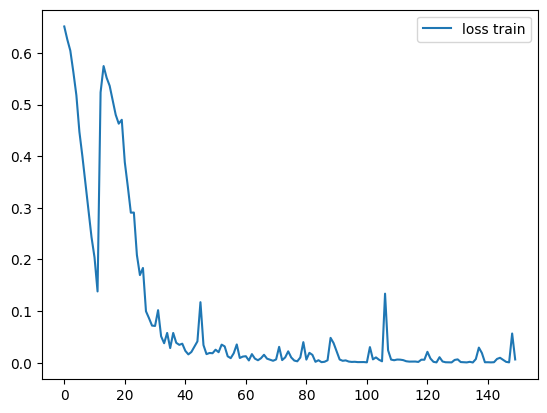

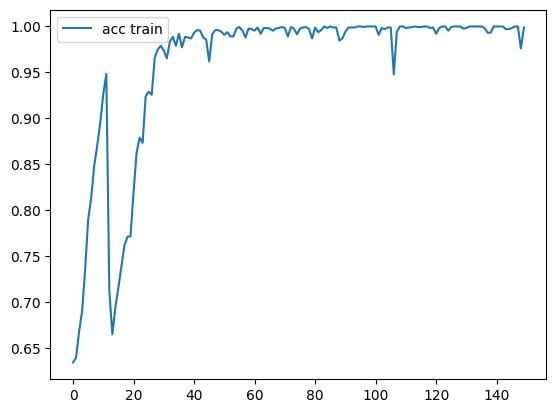

2026-10-10 18:38:50.738544: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 47520000 exceeds 10% of free system memory.


55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step

Fold 1 – Treino (AL excluído):
  Bronquite: 1.0000
  Infarto: 1.0000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step
Fold 1 – Validação (AL): acc = 1.0000
  Bronquite: 1.0000
  Infarto: 1.0000


2026-10-10 18:38:51.757778: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 48600000 exceeds 10% of free system memory.


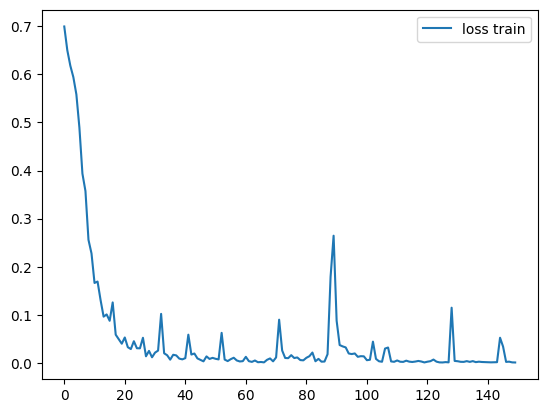

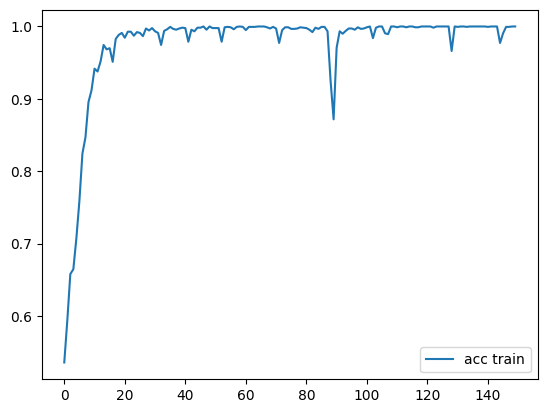

2026-10-10 18:40:56.468938: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 48600000 exceeds 10% of free system memory.


57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step

Fold 2 – Treino (e0 excluído):
  Bronquite: 1.0000
  Infarto: 1.0000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step
Fold 2 – Validação (e0): acc = 1.0000
  Bronquite: 1.0000
  Infarto: 1.0000


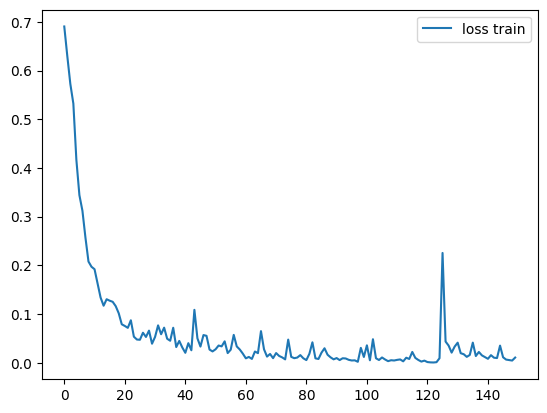

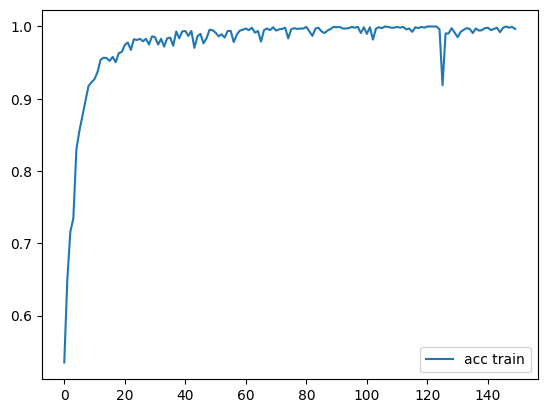

55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step

Fold 3 – Treino (e1 excluído):
  Bronquite: 1.0000
  Infarto: 0.9989
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 260ms/step
Fold 3 – Validação (e1): acc = 1.0000
  Bronquite: 1.0000
  Infarto: 1.0000


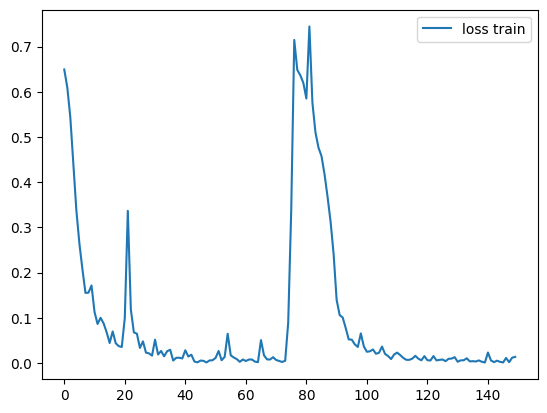

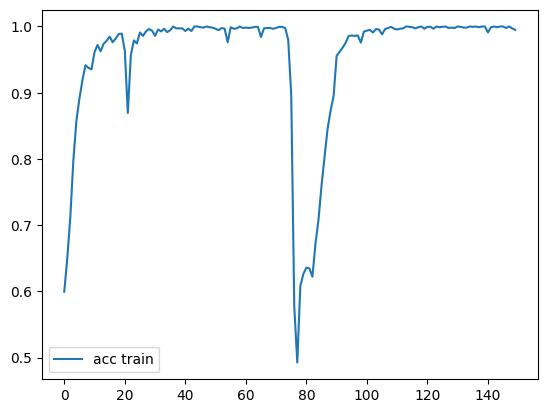

55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

Fold 4 – Treino (e2 excluído):
  Bronquite: 1.0000
  Infarto: 1.0000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 287ms/step
Fold 4 – Validação (e2): acc = 1.0000
  Bronquite: 1.0000
  Infarto: 1.0000


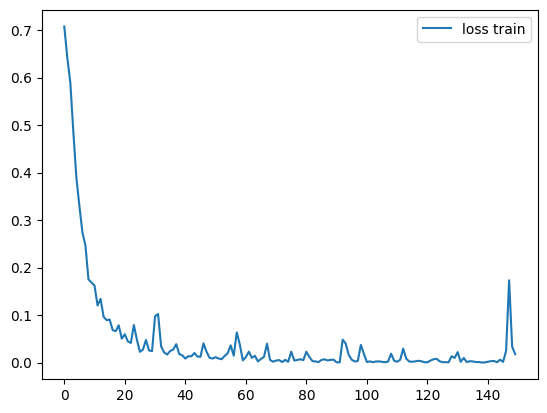

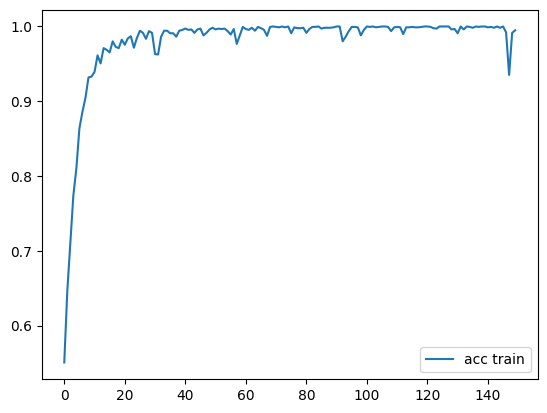

55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step

Fold 5 – Treino (e3 excluído):
  Bronquite: 1.0000
  Infarto: 0.9611
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step
Fold 5 – Validação (e3): acc = 0.9000
  Bronquite: 1.0000
  Infarto: 0.8000


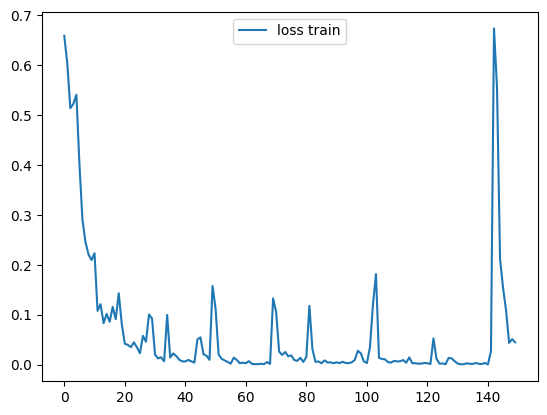

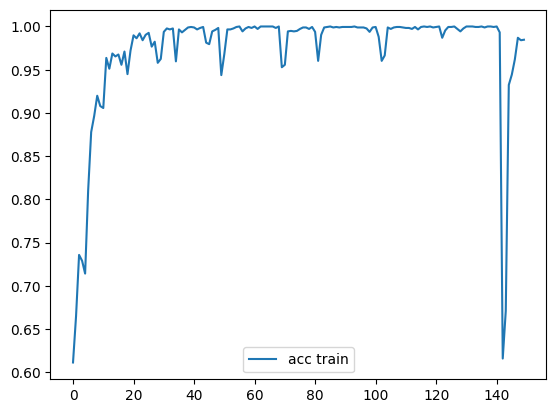

55/55 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step

Fold 6 – Treino (ME excluído):
  Bronquite: 0.9977
  Infarto: 0.9989
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 254ms/step
Fold 6 – Validação (ME): acc = 1.0000
  Bronquite: 1.0000
  Infarto: 1.0000


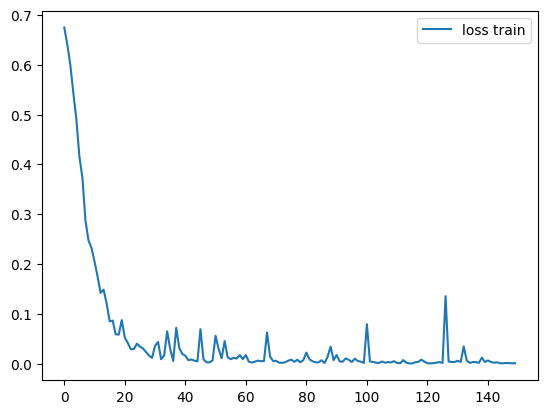

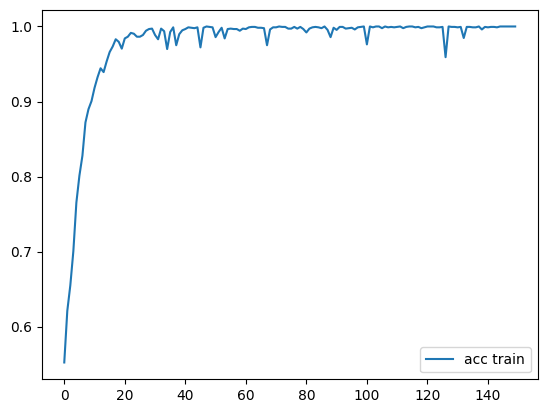

55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

Fold 7 – Treino (MV excluído):
  Bronquite: 1.0000
  Infarto: 1.0000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 224ms/step
Fold 7 – Validação (MV): acc = 1.0000
  Bronquite: 1.0000
  Infarto: 1.0000


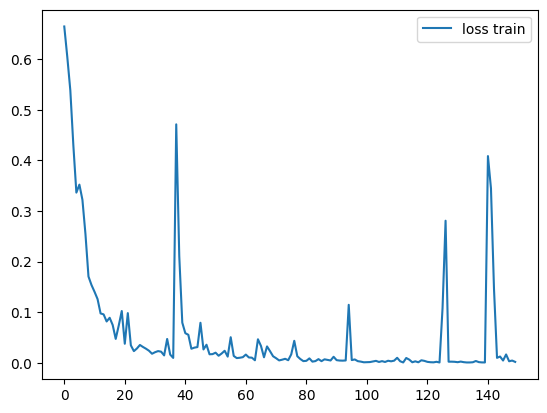

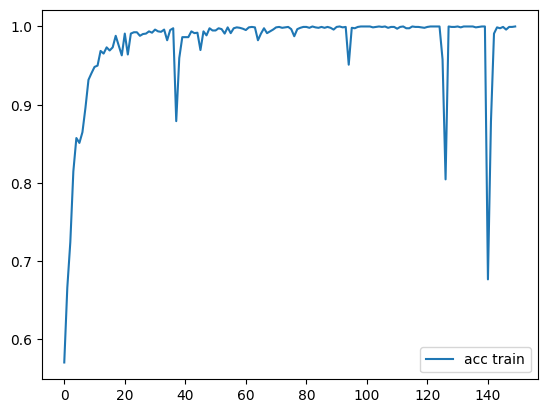

55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

Fold 8 – Treino (RO excluído):
  Bronquite: 1.0000
  Infarto: 1.0000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 215ms/step
Fold 8 – Validação (RO): acc = 1.0000
  Bronquite: 1.0000
  Infarto: 1.0000


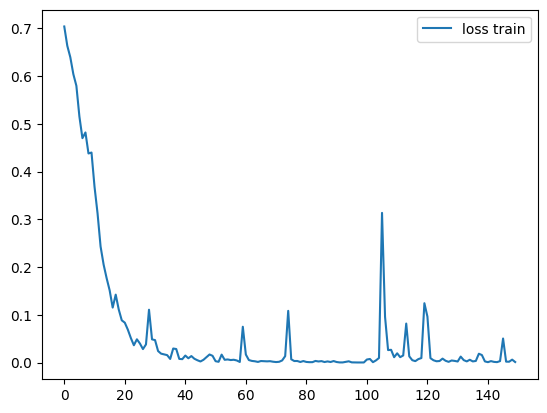

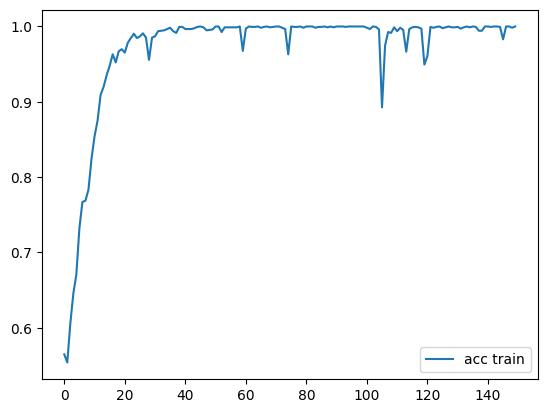

55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

Fold 9 – Treino (SA excluído):
  Bronquite: 1.0000
  Infarto: 1.0000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step
Fold 9 – Validação (SA): acc = 0.7000
  Bronquite: 1.0000
  Infarto: 0.4000


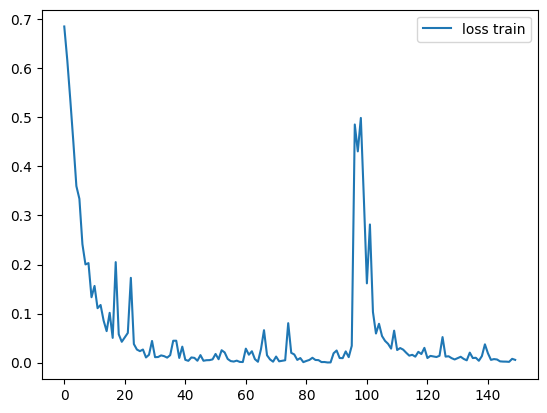

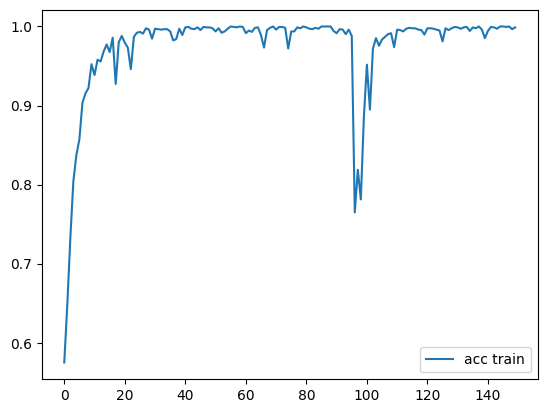

55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step

Fold 10 – Treino (MI excluído):
  Bronquite: 1.0000
  Infarto: 1.0000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step
Fold 10 – Validação (MI): acc = 1.0000
  Bronquite: 1.0000
  Infarto: 1.0000

Acurácia Total = 0.9600  |  Desvio = 0.0917
Acurácia Geral = 0.9592


In [8]:
#Listas para juntar as predições de todos os folds
yhat_all = []
ytrue_all = []
fold_results = []

def class_acc(true, pred, labels):
    #Retorna a acurácia de cada classe
    acc = {}
    for i,lbl in enumerate(labels):
        idx = np.where(true == i)[0]
        acc[lbl] = np.mean(pred[idx]==true[idx]) if len(idx)>0 else 0
    return acc

labels = list(label_map.keys())

#Cada fold deixa um sujeito de fora para a validação
for i, val_subj in enumerate(subject_names):
    #Validação: sujeito excluído. Treino: todos os demais
    X_val, y_val = subject_data[val_subj]['X_first'], subject_data[val_subj]['y_first']

    X_train = np.concatenate([subject_data[s]['X_all'] for s in subject_names if s != val_subj])
    y_train = np.concatenate([subject_data[s]['y_all'] for s in subject_names if s != val_subj])

    model = Sequential()
    model.add(InputLayer(input_shape=(num_frames, 225)))
    model.add(Masking(mask_value=0.0))
    model.add(LSTM(neuronios,
        activation='relu',
        return_sequences=False,
        recurrent_dropout=dropout_recorrente))
    model.add(Dense(2, activation='softmax'))
    model.compile(optimizer=AdamW(taxa_aprendizado, weight_decay=weight_decay),
                  loss='categorical_crossentropy',
                  metrics=['categorical_accuracy'])

    hist = model.fit(X_train, y_train,
                     batch_size=batch_size, epochs=epocas, verbose=0)
    model.save(f"{pasta_modelos}/model_fold_{i+1}.keras")

    plt.plot(hist.history['loss'], label='loss train')
    plt.legend()
    plt.show()
    plt.plot(hist.history['categorical_accuracy'], label='acc train')
    plt.legend()
    plt.show()

    #Acurácia por classe no treino
    y_pred_tr = np.argmax(model.predict(X_train), axis=1)
    y_true_tr = np.argmax(y_train, axis=1)
    print(f"\nFold {i+1} – Treino ({val_subj} excluído):")
    for lbl, a in class_acc(y_true_tr, y_pred_tr, labels).items():
        print(f"  {lbl}: {a:.4f}")

    #Acurácia por classe na validação
    y_pred_v = np.argmax(model.predict(X_val), axis=1)
    y_true_v = np.argmax(y_val, axis=1)
    yhat_all.append(y_pred_v)
    ytrue_all.append(y_true_v)

    acc_v = np.mean(y_pred_v == y_true_v)
    fold_results.append(acc_v)
    print(f"Fold {i+1} – Validação ({val_subj}): acc = {acc_v:.4f}")
    for lbl, a in class_acc(y_true_v, y_pred_v, labels).items():
        print(f"  {lbl}: {a:.4f}")

#Média e desvio padrão da acurácia entre os folds
media = np.mean(fold_results)
std = np.std(fold_results)
print(f"\nAcurácia Total = {media:.4f}  |  Desvio = {std:.4f}")

#Acurácia geral, juntando as predições de todos os folds
y_true_final = np.concatenate(ytrue_all)
y_pred_final = np.concatenate(yhat_all)
acc_final = np.mean(y_pred_final == y_true_final)
print(f"Acurácia Geral = {acc_final:.4f}")

## Modelo final (treinado com todos os dados)

Shape X_all: (1960, 30, 225)
Shape y_all: (1960, 2)
Epoch 1/150
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - categorical_accuracy: 0.6153 - loss: 0.6546
Epoch 2/150
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - categorical_accuracy: 0.6260 - loss: 0.6299
Epoch 3/150
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - categorical_accuracy: 0.7628 - loss: 0.5225
Epoch 4/150
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - categorical_accuracy: 0.7867 - loss: 0.4634
Epoch 5/150
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - categorical_accuracy: 0.8240 - loss: 0.3988
Epoch 6/150
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - categorical_accuracy: 0.8214 - loss: 0.4057
Epoch 7/150
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - categorical_accuracy: 0.8781 - loss: 0.2924
Epoch 8/150
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - categorical_accuracy: 0.8969 - loss: 0.2442
Epoch 9/150
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - categorical_accuracy: 0.9194 - loss: 0.1983
Epoch 10/150
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - categorical

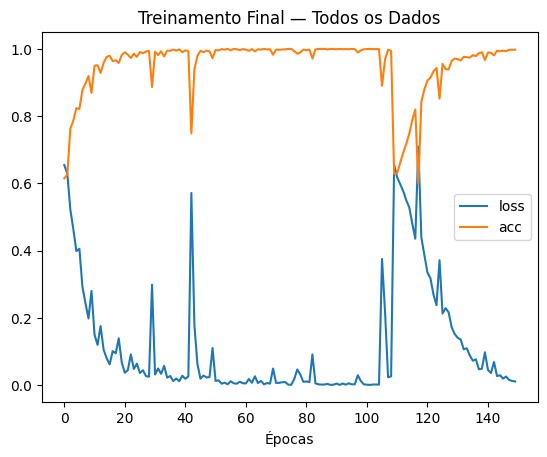

62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step

Acurácia total (auto-avaliação): 0.9985


In [9]:
#Junta os dados de treino de todos os sujeitos
X_all = np.concatenate([subject_data[s]['X_all'] for s in subject_names])
y_all = np.concatenate([subject_data[s]['y_all'] for s in subject_names])

print(f"Shape X_all: {X_all.shape}")
print(f"Shape y_all: {y_all.shape}")

model = Sequential()
model.add(InputLayer(input_shape=(num_frames, 225)))
model.add(Masking(mask_value=0.0))
model.add(LSTM(neuronios,
               activation='relu',
               return_sequences=False,
               recurrent_dropout=dropout_recorrente))
model.add(Dense(2, activation='softmax'))
model.compile(optimizer=AdamW(taxa_aprendizado, weight_decay=weight_decay),
              loss='categorical_crossentropy',
              metrics=['categorical_accuracy'])

#Treina com todos os sujeitos (X_all e y_all)
hist = model.fit(X_all, y_all,
                 batch_size=batch_size,
                 epochs=epocas,
                 verbose=1)

model.save(f"{pasta_modelos}/model_final_bro_inf.keras")

#Curvas de perda e acurácia do treino
plt.plot(hist.history['loss'], label='loss')
plt.plot(hist.history['categorical_accuracy'], label='acc')
plt.legend()
plt.title("Treinamento Final — Todos os Dados")
plt.xlabel("Épocas")
plt.show()

#Acurácia do modelo final nos próprios dados de treino
y_pred = np.argmax(model.predict(X_all), axis=1)
y_true = np.argmax(y_all, axis=1)

acc_final = np.mean(y_pred == y_true)
print(f"\nAcurácia total (auto-avaliação): {acc_final:.4f}")